(dro_lot_sizing:title)=
# Adaptive Distributionally Robust Lot-Sizing 

In this example, we will use RSOME to solve the lot-sizing problem discussed in {cite:ps}`Bertsimas_Shtern_Surt2022two`. This problem was formulated as a two-stage robust in [Adaptive Robust Lot-Sizing](aro_lot_sizing:title), and here we will adopt the same setting, where a capacitated network with $N$ locations is considered, and each location $i$ has a random demand $d_i$. The demand is supplied by the existing local stock $x_i$ or by transporting an amount $y_{ij}$ of units from another location $j$, which is determined after the demand is realized. Such a lot-sizing problem is formulate it as the following two-stage distributionally robust model to minimize the worst-case expected total cost:

```{math}
\begin{aligned}
\min~&\sum\limits_{i=1}^Nc_ix_i + \sup\limits_{\mathbb{P}\in\mathcal{F}}\mathbb{E}_{\mathbb{P}}\left[
Q(\pmb{x}, \tilde{\pmb{d}})\right] \\
\text{s.t. }&0\leq x_i \leq K &&\forall i\in[N],
\end{aligned}
```

where the recourse problem $Q(\pmb{x}, \pmb{d})$ is written as

```{math}
\begin{aligned}
Q(\pmb{x}, \pmb{d}) = \min~&\sum\limits_{i=1}^N\sum\limits_{j=1}^Nc_{ij}y_{ij} \\
\text{s.t. }&x_i - \sum\limits_{j=1}^Ny_{ij} + \sum\limits_{j=1}^Ny_{ji} \geq d_i &&\forall i \in [N] \\
&\pmb{y}\in\mathbb{R}_+^{N\times N}
\end{aligned}
```

In the following numerical studies, parameters are configured similar to [Adaptive Robust Lot-Sizing](aro_lot_sizing:title): there are $N=15$ locations and their coordinates are generated uniformly at random from $[0, 10]^2$. The cost of each local stock is $c_i=20$, and the shifting cost $t_{ij}$ is calculated as the Euclidean distance between store $i$ and store $j$. The stock capacity $K_i$ for at all locations are set to be $20$ units, and the capacity of product shifting is $b_{ij}=K/(n-1)u_{ij}$, where $u_{ij}$ are i.i.d. random variables generated from a standard uniform distribution. These parameters are defined in the code below.

In [1]:
import numpy as np

N = 15                                           # the total number of locations
c = 20 * np.ones(N)                              # the storage cost at each location
K = 20 * np.ones(N)                              # The maximum stock capacity

np.random.seed(1)
xy = 10*np.random.rand(2, N)                     # randomly generated locations in a 2D space
t = ((xy[[0]] - xy[[0]].T) ** 2 +
     (xy[[1]] - xy[[1]].T) ** 2) ** 0.5          # the shifting costs as the Euclidean distances
b = K/(N-1) * np.random.rand(N, N)               # the capacity of product shifting

The empirical distribution of the random demand $\tilde{\pmb{d}}$ is represented by a sample dataset of $S=16$ records generated uniformly at random from $[0, d^{\max}]^N$, where $d^{\max}=20$.

In [2]:
dmax = 20
S = 16

ds = dmax * np.random.rand(S, N)

## Sample Average Approximation

We firstly formulate the model in a sample average approximation (SAA) approach, where $\mathcal{F}$ is a singleton set containing only the empirical distribution:

```{math}
\mathcal{F} = \left\{
\mathbb{P}\in\mathcal{P}\left(\mathbb{R}^N\times[S]\right) \left|
\begin{array}{ll}
(\tilde{\pmb{d}}, s)\sim \mathbb{P} \\
\mathbb{P}\left[\left.\tilde{\pmb{d}}=\hat{\pmb{d}}_s\right|\tilde{s}=s\right] = 1 &\forall s\in[S] \\
\mathbb{P}\left[\tilde{\pmb{s}} = s \right] = 1/S &\forall s\in[S]
\end{array}
\right.
\right\},
```

where $\hat{\pmb{d}}_s$ is the $s$th sample of the empirical distribution. Notice that in the SAA model, the wait-and-see decision $y_{ij}$ adapts to each sample record, hence the adaptation rule is specified as $y_{ij}\in\mathcal{A}(\{\{1\}, \{2\}, ..., \{S\}\})$. Such a model is formulated and solved by the following code.

In [3]:
from rsome import dro, E

model = dro.Model(S)

d = model.rvar(N)

fset = model.ambiguity()
for s in range(S):
    fset[s].suppset(d == ds[s])
pr = model.p
fset.probset(pr == 1/S)

x = model.dvar(N)
y = model.dvar((N, N))
y.adapt(*range(S))

model.minsup(c@x + E((t*y).sum()), forall=fset)
model.st(y.sum(axis=0) - y.sum(axis=1) + x >= d)
model.st(0 <= y, y <= b)
model.st(0 <= x, x <= K)

model.solve('copt')

Being solved by COPT 8.0.5...
Solution status: 1
Running time: 0.0657s


After the model is solved, the solution is saved as a variable named `x_saa`, and the minimum objective value is printed as follows.

In [4]:
x_saa = x.get()
print(f'Objective value: {model.get():.4f}')

Objective value: 3740.4456


## Sample Robust Optimization with Single-Policy Approximation

Now we formulate the lot-sizing problem as a two-stage sample robust optimization model introduced in {cite:ps}`Bertsimas_Shtern_Surt2022two`, where the ambiguity set is written as

```{math}
\mathcal{F} = \left\{
\mathbb{P}\in\mathcal{P}\left(\mathbb{R}^N\times[S]\right) \left|
\begin{array}{ll}
(\tilde{\pmb{d}}, s)\sim \mathbb{P} \\
\mathbb{P}\left[\left.\left\|\tilde{\pmb{d}}-\hat{\pmb{d}}_s\right\| \leq \epsilon \right|\tilde{s}=s\right] = 1 &\forall s\in[S] \\
\mathbb{P}\left[\tilde{\pmb{s}} = s \right] = 1/S &\forall s\in[S]
\end{array}
\right.
\right\},
```

where the scenario-wise support is a Euclidean norm with a radius of $\epsilon$ around the empirical data $\hat{\pmb{d}}_s$. We first use a single-policy affine adaptation (SP affine) $y_{ij}\in\overline{\mathcal{A}}(\{\{1, 2, ..., S\}\}, [N])$ to approximate the wait-and-see decision, which implies that $y_{ij}$ follows an affine function of the random variable $\pmb{d}$ across all samples. Suppose that the ambiguity set parameter $\epsilon=10S^{-1/10}$.

In [5]:
epsilon = 10*S**(-1/10)

The sample robust optimization model is then solved by the code below.

In [15]:
from rsome import dro, E
import rsome as rso

model = dro.Model(S)

d = model.rvar(N)

fset = model.ambiguity()
for s in range(S):
    fset[s].suppset(rso.norm(d - ds[s]) <= epsilon)
pr = model.p
fset.probset(pr == 1/S)

x = model.dvar(N)
y = model.dvar((N, N))
y.adapt(d)

model.minsup(c@x + E((t*y).sum()), forall=fset)
model.st(y.sum(axis=0) - y.sum(axis=1) + x >= d)
model.st(0 <= y, y <= b)
model.st(0 <= x, x <= K)

model.solve('copt')

Being solved by COPT 8.0.5...
Solution status: 1
Running time: 2.6954s


The solution is saved as a variable named `x_srsp`, and the minimum objective value is printed as follows.

In [16]:
x_srsp = x.get()
print(f'Objective value: {model.get():.4f}')

Objective value: 4464.2234


## Sample Robust Optimization with Multiple-Policy Approximation

The SP affine approximation above can be extended to a multiple-policy affine adaptation (MP affine) version, where the wait-and-see decision $y_ij$ follows affine functions of the random demand $\pmb{d}$, and coefficients of these functions may vary under different sample realizations. In other words, $y_{ij} \in \overline{\mathcal{A}}(\{\{1\}, \{2\}, ..., \{S\}\}, [N])$. The code is slightly changed as follows.

In [8]:
from rsome import dro, E
import rsome as rso

model = dro.Model(S)             # define a model

d = model.rvar(N)

fset = model.ambiguity()
for s in range(S):
    fset[s].suppset(rso.norm(d - ds[s]) <= epsilon)
pr = model.p
fset.probset(pr == 1/S)

x = model.dvar(N)               # here-and-now location decisions
y = model.dvar((N, N))          # wait-and-see transportation decisions
y.adapt(*range(S))
y.adapt(d)

model.minsup(c@x + E((t*y).sum()), forall=fset)
model.st(y.sum(axis=0) - y.sum(axis=1) + x >= d)
model.st(y >= 0)
model.st(0 <= x, x <= K)

model.solve('copt')

Being solved by COPT 8.0.5...
Solution status: 1
Running time: 0.7383s


In [9]:
x_srmp = x.get()
print(f'Objective value: {model.get():.4f}')

Objective value: 4343.6864


## Visualization of the Optimal Decisions

The optimal decisions yielded from the three models above are visualized in the following figure.

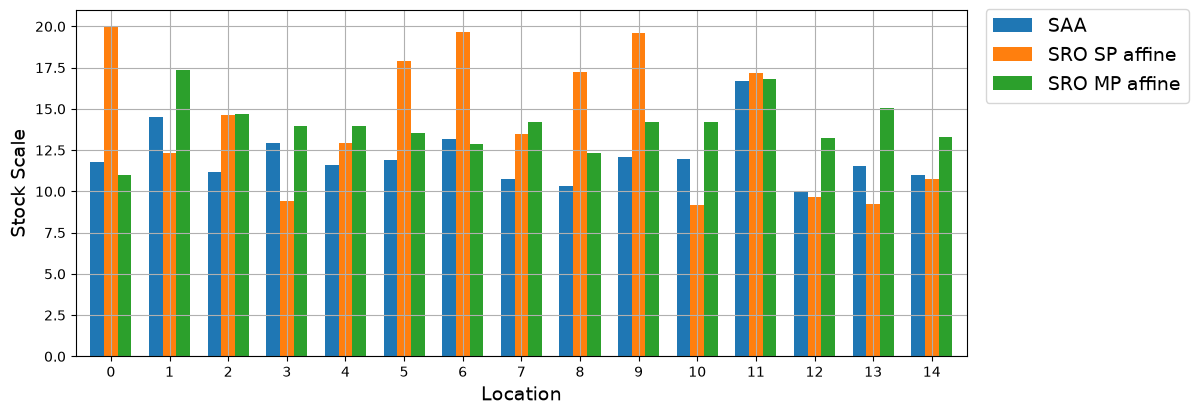

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(11.5, 4.5))
results = pd.DataFrame({'SAA': x_saa,
                        'SRO SP affine': x_srsp,
                        'SRO MP affine': x_srmp})

results.plot(kind='bar', width=0.7, ax=axes)
plt.xticks(rotation=0)
plt.xlabel('Location', fontsize=14)
plt.ylabel('Stock Scale', fontsize=14)
plt.legend(bbox_to_anchor=(1.01, 1.03), fontsize=14)
plt.grid()
plt.show()

<br>

---

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```